**Importing Necessary Liabraries :-**

In [1]:
# Import Liabraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

**Connecting Python to PostgreSQL :-**

In [2]:
user = 'postgres'
password = '636301'
host = 'localhost'
port = 5432
database = 'Taxi_Analysis_db'
engine = create_engine(f'postgresql://{user}:{password}@{host}:{port}/{database}')

**Loading CSV Data to PostgreSQL :-**

In [3]:
table_name = "raw_yellow_tripdata"

In [4]:
# file_path = r"D:\NYC\yellow_tripdata.csv"


# df = pd.read_csv(file_path, parse_dates=["tpep_pickup_datetime", "tpep_dropoff_datetime"],low_memory=False)
# df.to_sql(table_name, engine, if_exists="replace", index=False)

# print(f"Loaded {table_name}: {len(df)} rows")

**Importing Data in python from PostgreSQL :-**

In [5]:
sql_query="""
          SELECT table_name AS name FROM information_schema.tables
          WHERE table_schema = 'public'
"""

df = pd.read_sql(f"SELECT * FROM {table_name}", engine) 

In [6]:
df.shape

(4090836, 20)

### **Data Overview in Table 1 (Yellow_Tripdata Table) :-**

**Data Dictionary :-**

1)-**VendorID**             : Code that tells us which taxi company or system recorded the trip.

2)-**tpep_pickup_datetime**    : The exact date and time when the passenger was picked up.

3)-**tpep_dropoff_datetime**   : The exact date and time when the passenger was dropped off.

4)-**passenger_count**         : Number of passengers in the trip. Entered by the driver, so may not always be accurate.

5)-**trip_distance**            : Distance of the trip in miles, measured by the taxi meter.

6)-**RatecodeID**             : Tells us which fare/rate type was used.
1 = Standard, 2 = JFK, 3 = Newark, 4 = Nassau/Westchester, 5 = Negotiated fare, 6 = Group ride, 99 = Unknown.
                          
7)-**store_and_fwd_flag**       : Whether trip data was stored in the taxi first and sent to the server later due to a network problem. Y = Yes, N = No.

8)-**PULocationID**             : ID of the pickup location/taxi zone (matches NYC taxi zone lookup table).

9)-**DOLocationID**              : ID of the drop-off location/taxi zone.

10)-**payment_type**             : How the passenger paid.
1 = Credit card, 2 = Cash, 3 = No charge, 4 = Dispute.Other codes represent less common cases.

11)-**fare_amount**               : The basic taxi fare charged, before extra charges, taxes, tips, and other fees.

12)-**extra**                     : Extra charges added to the fare, such as rush-hour or overnight charges.

13)-**mta_tax**                  : A tax collected for the Metropolitan Transportation Authority (MTA).

14)-**tip_amount**                 : Recorded tip amount. Card tips are recorded by the system; cash tips are generally not recorded in this field.

15)-**tolls_amount**               : Total amount of tolls paid during the trip.

16)-**improvement_surcharge**      : A small surcharge used to support taxi-related improvements.

17)-**total_amount**                : Total recorded amount charged for the trip, including fare, extras,
taxes, tips, tolls, and applicable surcharges. It is not profit.

18)-**congestion_surcharge**        : A congestion-related extra charge recorded for eligible trips
under the applicable NYC taxi surcharge rules.

19)-**Airport_fee**                  : An extra airport-related fee charged when the trip meets
the applicable airport fee rules.

20)-**cbd_congestion_fee**            : A congestion fee related to NYC's Central Business District (CBD)
congestion pricing rules.

In [7]:
df.columns

Index(['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime',
       'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag',
       'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra',
       'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge',
       'total_amount', 'congestion_surcharge', 'Airport_fee',
       'cbd_congestion_fee'],
      dtype='object')

In [8]:
# Checking Top 5 rows of the dataset
df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,2,2026-05-01 00:04:59,2026-05-01 00:32:48,1.0,7.51,1.0,N,138,37,2,35.9,6.00,0.5,0.00,0.0,1.0,45.40,0.0,2.0,0.00
1,2,2026-05-01 00:37:05,2026-05-01 00:59:47,1.0,6.14,1.0,N,138,237,1,27.5,6.00,0.5,9.56,0.0,1.0,49.81,2.5,2.0,0.75
2,1,2026-05-01 00:34:05,2026-05-01 00:54:02,1.0,2.40,1.0,N,249,232,1,19.1,4.25,0.5,3.73,0.0,1.0,28.58,2.5,0.0,0.75
3,1,2026-05-01 00:55:07,2026-05-01 01:02:43,0.0,1.20,1.0,N,232,114,1,9.3,4.25,0.5,3.00,0.0,1.0,18.05,2.5,0.0,0.75
4,7,2026-05-01 00:44:13,2026-05-01 00:44:13,2.0,0.86,1.0,N,140,237,1,7.2,0.00,0.5,2.44,0.0,1.0,14.64,2.5,0.0,0.00


In [9]:
# Checking Bottom 5 rows of the dataset
df.tail()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
4090831,2,2026-05-31 23:35:12,2026-05-31 23:51:04,NaN,5.11,NaN,None,74,243,0,17.19,0.0,0.5,0.0,0.0,1.0,18.69,NaN,NaN,0.00
4090832,1,2026-05-31 23:48:01,2026-06-01 00:05:57,NaN,8.80,NaN,None,129,130,0,27.98,0.0,0.5,0.0,0.0,1.0,33.48,NaN,NaN,0.00
4090833,2,2026-05-31 23:48:50,2026-06-01 00:03:52,NaN,6.47,NaN,None,48,116,0,24.12,0.0,0.5,0.0,0.0,1.0,28.87,NaN,NaN,0.75
4090834,2,2026-05-31 23:23:13,2026-05-31 23:38:35,NaN,2.94,NaN,None,113,256,0,18.20,0.0,0.5,0.0,0.0,1.0,22.95,NaN,NaN,0.75
4090835,2,2026-05-31 23:41:51,2026-05-31 23:47:32,NaN,0.83,NaN,None,255,112,0,7.02,0.0,0.5,0.0,0.0,1.0,8.52,NaN,NaN,0.00


In [10]:
# Checking 10 Random 10 Rows  of the dataset
df.sample(10)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
3512378,2,2026-05-14 17:21:26,2026-05-14 18:04:50,NaN,0.01,NaN,None,166,170,0,50.85,0.00,0.5,0.00,0.00,1.0,54.85,NaN,NaN,0.00
2971864,2,2026-05-30 09:31:44,2026-05-30 10:11:12,3.0,10.38,1.0,N,138,158,1,47.10,5.00,0.5,12.86,7.46,1.0,79.17,2.5,2.0,0.75
2272097,1,2026-05-22 12:21:31,2026-05-22 12:57:22,1.0,3.50,1.0,N,143,170,1,28.20,3.25,0.5,6.60,0.00,1.0,39.55,2.5,0.0,0.75
1786185,2,2026-05-17 21:05:01,2026-05-17 21:26:57,1.0,3.98,1.0,N,237,246,1,23.30,1.00,0.5,5.81,0.00,1.0,34.86,2.5,0.0,0.75
998034,2,2026-05-10 17:52:11,2026-05-10 18:02:42,2.0,1.00,1.0,N,163,161,1,10.00,0.00,0.5,2.95,0.00,1.0,17.70,2.5,0.0,0.75
2308900,2,2026-05-22 18:24:56,2026-05-22 18:33:47,1.0,0.96,1.0,N,239,143,1,10.00,2.50,0.5,1.50,0.00,1.0,18.00,2.5,0.0,0.00
2800285,2,2026-05-28 17:36:01,2026-05-28 17:53:12,1.0,2.09,1.0,N,140,238,1,16.30,2.50,0.5,4.56,0.00,1.0,27.36,2.5,0.0,0.00
63204,2,2026-05-01 17:15:12,2026-05-01 18:10:15,2.0,10.75,1.0,N,138,25,1,52.70,7.50,0.5,7.00,0.00,1.0,70.70,0.0,2.0,0.00
2965843,2,2026-05-30 07:46:16,2026-05-30 07:52:22,1.0,1.13,1.0,N,143,163,1,8.60,0.00,0.5,2.67,0.00,1.0,16.02,2.5,0.0,0.75
2456324,2,2026-05-24 16:47:06,2026-05-24 16:49:32,1.0,0.31,1.0,N,48,50,2,4.40,0.00,0.5,0.00,0.00,1.0,9.15,2.5,0.0,0.75


In [11]:
# Checking the shape of the dataset (Number of rows and columns)
print('Total Rows in Customer Table :',df.shape[0])
print('Total Columns in Customer Table :',df.shape[1])

Total Rows in Customer Table : 4090836
Total Columns in Customer Table : 20


In [12]:
# Getting information about our dataset like total rows,
# columns,datatypes of each column and memory requirement.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4090836 entries, 0 to 4090835
Data columns (total 20 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int64         
 1   tpep_pickup_datetime   datetime64[ns]
 2   tpep_dropoff_datetime  datetime64[ns]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     object        
 7   PULocationID           int64         
 8   DOLocationID           int64         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  Airport_fee           

In [13]:
# Checking % for missing dataset in each column
round(df.isnull().mean()*100,2)

VendorID                  0.00
tpep_pickup_datetime      0.00
tpep_dropoff_datetime     0.00
passenger_count          23.35
trip_distance             0.00
RatecodeID               23.35
store_and_fwd_flag       23.35
PULocationID              0.00
DOLocationID              0.00
payment_type              0.00
fare_amount               0.00
extra                     0.00
mta_tax                   0.00
tip_amount                0.00
tolls_amount              0.00
improvement_surcharge     0.00
total_amount              0.00
congestion_surcharge     23.35
Airport_fee              23.35
cbd_congestion_fee        0.00
dtype: float64

In [14]:
# Checking not null values in each column
df.notnull().sum()

VendorID                 4090836
tpep_pickup_datetime     4090836
tpep_dropoff_datetime    4090836
passenger_count          3135465
trip_distance            4090836
RatecodeID               3135465
store_and_fwd_flag       3135465
PULocationID             4090836
DOLocationID             4090836
payment_type             4090836
fare_amount              4090836
extra                    4090836
mta_tax                  4090836
tip_amount               4090836
tolls_amount             4090836
improvement_surcharge    4090836
total_amount             4090836
congestion_surcharge     3135465
Airport_fee              3135465
cbd_congestion_fee       4090836
dtype: int64

In [15]:
# Checking total duplicated values available in the dataset.
duplicate_values=df.duplicated().sum()
print('Total Duplicate Values :',duplicate_values)

Total Duplicate Values : 0


In [16]:
# Create a copy of dataset before analysing.
df1=df.copy()

### **Data Cleaning in Table 1 (Yellow_Tripdata Table) :-**

In [17]:
# What to fix in table 1 (Yellow Trip Data).
# 1)-Need to change data type from float to int for columns-passenger_count/RatecodeID.
# 2)-Need to check negative values columns and fix them.
# 3)-Need to check value(0) in trip_distance columnand also fix invalid distance.
# 4)-Need to check extreme value(180) in fare_amount. Total_amount vs all other amount column sum comparision.Also replace non zero tip which payment mode is cash with NaN.
# 5)-Need to handle null values in columns-passenger_count/RatecodeID/store_and_fwd_flag/congestion_surcharge/Airport_fee.
# 6)- Need to remove values(264,265) from DOLocationID column.
# 7)- Need to check trip_distance>100 miles.(if fare_amount is also unusually high and RatecodeID shows something like negotiated fare, it's probably a real (if rare) long trip)
# 8)- Add new column as pickup_hour.

### 1)-Need to change data type from float to int for columns-passenger_count/RatecodeID.


In [18]:
df[['passenger_count','RatecodeID']] = df[['passenger_count','RatecodeID']].astype('Int64')

In [19]:
df[['passenger_count','RatecodeID']].dtypes

passenger_count    Int64
RatecodeID         Int64
dtype: object

### 2)-Need to check negative values columns and fix them.


In [20]:
# Negative value percentage in numeric columns.

negative_cols = ['fare_amount','extra','mta_tax','tip_amount','tolls_amount','improvement_surcharge','total_amount','congestion_surcharge','Airport_fee','cbd_congestion_fee']

df[negative_cols].apply(lambda x : x.lt(0).mean()*100)

fare_amount              0.347875
extra                    0.182750
mta_tax                  0.342742
tip_amount               0.001076
tolls_amount             0.026596
improvement_surcharge    0.358118
total_amount             0.363666
congestion_surcharge     0.290307
Airport_fee              0.056883
cbd_congestion_fee       0.236798
dtype: float64

##### *Negative values were found in fare/charge-related columns. Since negative values are invalid for these monetary fields and affected only 0.36% of the records, those records were removed.*

In [21]:
# Store negative-value rows before removing them for future reference and review.

numeric_cols = df.select_dtypes(include='number').columns

negative_cols = numeric_cols[(df[numeric_cols]<0).any()]

negative_cols_values = df.loc[(df[negative_cols]<0).any(axis=1), negative_cols]

negative_cols_values

,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
26,-12.80,-1.00,-0.5,0.00,0.00,-1.0,-18.55,-2.5,0.0,-0.75
107,-3.70,-1.00,-0.5,0.00,0.00,-1.0,-9.45,-2.5,0.0,-0.75
274,-30.30,-1.00,-0.5,0.00,0.00,-1.0,-36.05,-2.5,0.0,-0.75
386,-12.10,-1.00,-0.5,0.00,0.00,-1.0,-17.85,-2.5,0.0,-0.75
456,-24.00,-1.00,-0.5,0.00,0.00,-1.0,-29.75,-2.5,0.0,-0.75
...,...,...,...,...,...,...,...,...,...,...
3991915,84.15,-0.75,0.0,0.00,14.79,1.0,100.69,NaN,NaN,0.75
4023323,-2.59,0.00,0.5,3.32,0.00,1.0,5.48,NaN,NaN,0.75
4038508,-1.12,0.00,0.5,1.18,0.00,1.0,4.81,NaN,NaN,0.75
4048345,-0.95,0.00,0.5,0.00,29.58,1.0,32.63,NaN,NaN,0.00


In [22]:
# Drop Negative value columns

negative_cols = [
    'fare_amount', 'extra', 'mta_tax', 'tip_amount',
    'tolls_amount', 'improvement_surcharge', 'total_amount',
    'congestion_surcharge', 'Airport_fee', 'cbd_congestion_fee'
]

df.drop(df.index[(df[negative_cols] < 0).any(axis=1)],inplace=True)

In [23]:
(df[negative_cols] < 0).any(axis=1).sum()

np.int64(0)

In [24]:
df.shape

(4075883, 20)

### 3)-Need to check value(0) in trip_distance column and also fix invalid distance.


In [25]:
zero_count = (df['trip_distance'] == 0).sum()
zero_percentage = (df['trip_distance'] == 0).mean() * 100

print("Zero values:", zero_count)
print("Percentage:", round(zero_percentage, 2), "%")

Zero values: 111259
Percentage: 2.73 %


In [26]:
# Replace trip_distance = 0 with missing (NA)
df.loc[df['trip_distance'] == 0, 'trip_distance'] = pd.NA

**trip_distance = 0** are real trips where the distance meter/GPS just didn't record properly — but a fare was still charged.Dropping all of these rows would throw away real revenue data. 

We should replace 0 with NaN (missing).so it doesn't quietly get counted as "0 miles" in distance-based averages later, while the fare amount stays intact for revenue analysis.

In [27]:
# Recheck

zero_count = (df['trip_distance'] == 0).sum()
zero_percentage = (df['trip_distance'] == 0).mean() * 100

print("Zero values:", zero_count)
print("Percentage:", round(zero_percentage, 2), "%")

Zero values: 0
Percentage: 0.0 %


In [28]:
# Check if dropoff time is before/equal to pickup time (impossible trip)
df['trip_duration_min'] = ((
    df['tpep_dropoff_datetime'] - df['tpep_pickup_datetime']
).dt.total_seconds()/60).round(2)

# Flag rows where dropoff <= pickup (0 or negative duration)
df['is_invalid_time'] = df['trip_duration_min'] <= 0

print("Invalid time rows:", df['is_invalid_time'].sum())

Invalid time rows: 52063


In [29]:
df.loc[df['is_invalid_time'], 'trip_duration_min'] = pd.NA

In [30]:
df['is_invalid_date'] = df['tpep_pickup_datetime'] < '2026-01-01'
print(df['is_invalid_date'].sum())

2


In [31]:
df = df[~df['is_invalid_date']].copy()

In [32]:
# Convert trip_distance from miles to kilometers
df['trip_distance_km'] = (df['trip_distance'] * 1.60934).round(2)

In [33]:
# Check trip_distance_km directly for extreme values (independent of fare)
# NYC to the farthest reasonable point (e.g. Montauk, or a cross-country outlier check) is well under 200 miles
distance_threshold = df['trip_distance_km'].quantile(0.999983)
print("99.9th percentile trip_distance_km:", distance_threshold)

df['is_distance_outlier'] = df['trip_distance_km'] > distance_threshold
print("Distance outlier rows:", df['is_distance_outlier'].sum())

99.9th percentile trip_distance_km: 362.8730591470329
Distance outlier rows: 68


In [34]:
df.loc[df['is_distance_outlier'], 'trip_distance_km'] = pd.NA

### 4)-Need to check extreme value(180) in fare_amount. Total_amount vs all other amount column sum comparision. Also replace non zero tip which payment mode is cash with NaN.



In [35]:
df['fare_amount'].describe().round(2)

count    4075881.00
mean          21.67
std           18.76
min            0.00
25%           10.00
50%           16.30
75%           26.80
max         5525.99
Name: fare_amount, dtype: float64

In [36]:
# Calculate fare per mile (avoid divide-by-zero)
df['fare_per_mile'] = (df['fare_amount'] / df['trip_distance']).round(2).replace(0, pd.NA)

**Note** -> replace(0, pd.NA) does: it first swaps every 0 in trip_distance with NA (missing), so the division becomes fare_amount / NA, which pandas handles cleanly by returning NA instead of inf.

In [37]:
threshold = df['fare_per_mile'].quantile(0.99)
print('Threshold :',threshold)

Threshold : 46.321299999998885


In [38]:
zero_dist_threshold = df[(df['trip_distance'].isna()) & (df['fare_amount']>0)]['fare_amount'].quantile(0.99)
zero_dist_threshold

np.float64(120.0)

In [39]:
# Exclude JFK (2) and Negotiated (5) fares from Fare outliers.
df['is_fare_outlier'] = (
    (df['fare_per_mile'] > threshold) |
    ((df['trip_distance'].isna()) & (df['fare_amount'] > zero_dist_threshold))
) & (~df['RatecodeID'].isin([2, 5]))   

print("Total flagged fare outliers :", df['is_fare_outlier'].sum())

Total flagged fare outliers : 31966


In [40]:
# Checking all fare outliers.
pd.set_option('display.max_columns', None)
df[df['is_fare_outlier']]

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration_min,is_invalid_time,is_invalid_date,trip_distance_km,is_distance_outlier,fare_per_mile,is_fare_outlier
416,2,2026-05-01 00:33:58,2026-05-01 00:53:43,1,0.15,1,N,100,100,1,16.30,1.0,0.5,4.41,0.0,1.0,26.46,2.5,0.0,0.75,19.75,False,False,0.24,False,108.67,True
1249,2,2026-05-01 00:11:04,2026-05-01 00:14:34,1,0.04,1,N,138,265,1,5.10,6.0,0.5,18.00,0.0,1.0,32.60,0.0,2.0,0.00,3.50,False,False,0.06,False,127.5,True
1390,2,2026-05-01 00:51:19,2026-05-01 00:54:26,1,0.07,1,N,158,249,4,5.10,1.0,0.5,0.00,0.0,1.0,10.85,2.5,0.0,0.75,3.12,False,False,0.11,False,72.86,True
1811,2,2026-05-01 00:56:20,2026-05-01 00:58:25,1,0.09,1,N,164,164,1,4.40,1.0,0.5,2.03,0.0,1.0,12.18,2.5,0.0,0.75,2.08,False,False,0.14,False,48.89,True
1922,2,2026-05-01 00:19:55,2026-05-01 00:20:54,1,0.01,1,N,79,79,2,3.00,1.0,0.5,0.00,0.0,1.0,8.75,2.5,0.0,0.75,0.98,False,False,0.02,False,300.0,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4089716,2,2026-05-31 22:35:54,2026-05-31 22:37:16,<NA>,0.13,<NA>,None,181,181,0,8.72,0.0,0.5,0.00,0.0,1.0,15.22,NaN,NaN,0.00,1.37,False,False,0.21,False,67.08,True
4090350,2,2026-05-31 23:27:44,2026-05-31 23:30:58,<NA>,0.38,<NA>,None,246,143,0,26.07,0.0,0.5,0.00,0.0,1.0,30.82,NaN,NaN,0.75,3.23,False,False,0.61,False,68.61,True
4090355,2,2026-05-31 23:06:53,2026-05-31 23:07:56,<NA>,0.04,<NA>,None,68,186,0,15.65,0.0,0.5,0.00,0.0,1.0,20.40,NaN,NaN,0.75,1.05,False,False,0.06,False,391.25,True
4090817,2,2026-05-31 23:01:04,2026-05-31 23:04:28,<NA>,0.41,<NA>,None,152,116,0,19.12,0.0,0.5,0.00,0.0,1.0,20.62,NaN,NaN,0.00,3.40,False,False,0.66,False,46.63,True


In [41]:
# Replace fare_amount with NaN for flagged outliers (keep the rows)
df.loc[df['is_fare_outlier'], 'fare_amount'] = np.nan

In [42]:
# Check RatecodeID breakdown for all flagged fare outliers
df['fare_amount'].isnull().sum()

np.int64(31966)

In [43]:
# Remove rows where fare_amount is negative, as negative fare values are invalid.
df.drop(df[df['fare_amount'] < 0].index, inplace=True)

In [44]:
# Fill null fare amount if taxes, charges and total amount are present.

tax_charge_cols = ['extra','mta_tax','tip_amount','tolls_amount','improvement_surcharge',
                    'congestion_surcharge','Airport_fee','cbd_congestion_fee']

total_tax_charge = df[tax_charge_cols].sum(axis=1)

fare_fill = df[(df['fare_amount'].isnull() | (df['fare_amount']==0)) & (df['total_amount'] > total_tax_charge)]

fare_fill_with = (df.loc[fare_fill.index, 'total_amount'] - total_tax_charge.loc[fare_fill.index])

df.loc[fare_fill.index, 'fare_amount'] = fare_fill_with

In [45]:
df_clean = df.dropna(subset=['fare_amount'])

In [46]:
# Check for nonzero tip_amount on cash payments (payment_type = 2)
df['is_cash_tip_error'] = (df['payment_type'] == 2) & (df['tip_amount'] > 0)

print("Cash payments with a recorded tip:", df['is_cash_tip_error'].sum())

Cash payments with a recorded tip: 25


In [47]:
# Look at a sample before deciding
df[df['is_cash_tip_error']][
    ['payment_type', 'tip_amount']
].head()

,payment_type,tip_amount
174074,2,5.68
348014,2,9.81
362248,2,8.07
426459,2,20.20
499285,2,2.31


In [48]:
df.loc[df['is_cash_tip_error'], 'tip_amount'] = pd.NA

In [49]:
# Check if total_amount matches the sum of its components

component_cols = ['fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount',
                   'improvement_surcharge', 'congestion_surcharge', 'Airport_fee','cbd_congestion_fee']

df['expected_total'] = df[component_cols].sum(axis=1, skipna=False)
df['total_diff'] = (df['total_amount'] - df['expected_total']).abs().round(2)

# Allow a small tolerance (rounding) rather than exact match

df['is_total_mismatch'] = df['total_diff'] > 0.05

print("Mismatched total_amount rows:", df['is_total_mismatch'].sum())

Mismatched total_amount rows: 550780


In [50]:
# Look at a sample before deciding what to do
df[df['is_total_mismatch']][
    ['fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount',
     'improvement_surcharge', 'congestion_surcharge', 'Airport_fee',
     'total_amount', 'expected_total', 'total_diff']
].head(10)

,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,congestion_surcharge,Airport_fee,total_amount,expected_total,total_diff
2,19.1,4.25,0.5,3.73,0.00,1.0,2.5,0.0,28.58,31.83,3.25
3,9.3,4.25,0.5,3.00,0.00,1.0,2.5,0.0,18.05,21.30,3.25
4,7.2,0.00,0.5,2.44,0.00,1.0,2.5,0.0,14.64,13.64,1.00
6,9.3,3.50,0.5,2.85,0.00,1.0,2.5,0.0,17.15,19.65,2.50
13,5.8,4.25,0.5,0.00,0.00,1.0,2.5,0.0,11.55,14.80,3.25
16,19.8,4.25,0.5,5.10,0.00,1.0,2.5,0.0,30.65,33.90,3.25
17,9.3,4.25,0.5,3.75,0.00,1.0,2.5,0.0,18.80,22.05,3.25
20,70.0,4.50,0.5,12.51,7.46,1.0,2.5,2.0,95.97,100.47,4.50
43,8.6,4.25,0.5,2.85,0.00,1.0,2.5,0.0,17.20,20.45,3.25
44,10.0,4.25,0.5,3.15,0.00,1.0,2.5,0.0,18.90,22.15,3.25


**total_amount (mismatched rows)** --> Leave as missing (NA), don't guess.

After checking sum of fare amount with rest amounts, total_amount must be same. If not, we will replace total amount with NaN (Missing Values). [To fix the errors].

Why we didn't replace total amount with expected total= If any component value (fare amount with rest amounts) was recorded wrong then expected total will also calculate incorrectly.

In [51]:
df.loc[df['is_total_mismatch'], 'total_amount'] = pd.NA

In [52]:
df.isnull().sum()

VendorID                      0
tpep_pickup_datetime          0
tpep_dropoff_datetime         0
passenger_count          955293
trip_distance            111259
RatecodeID               955293
store_and_fwd_flag       955293
PULocationID                  0
DOLocationID                  0
payment_type                  0
fare_amount                   1
extra                         0
mta_tax                       0
tip_amount                   25
tolls_amount                  0
improvement_surcharge         0
total_amount             550780
congestion_surcharge     955293
Airport_fee              955293
cbd_congestion_fee            0
trip_duration_min         52063
is_invalid_time               0
is_invalid_date               0
trip_distance_km         111327
is_distance_outlier           0
fare_per_mile            113293
is_fare_outlier               0
is_cash_tip_error             0
expected_total           955318
total_diff               955318
is_total_mismatch             0
dtype: i

### 5)-Need to handle null values in columns-passenger_count/RatecodeID/store_and_fwd_flag/congestion_surcharge/Airport_fee.

##### 1- *passenger_count Column -  passenger_count contains approximately 23% missing values. Missing values are kept as NULL because the actual passenger count is unknown. Imputing with a fixed value or statistical value could introduce artificial data and distort passenger-count analysis.     Zero values are also converted to NULL because 0 passengers is not considered a valid passenger count for a recorded trip, and the actual value cannot be reliably determined.*

In [53]:
df['passenger_count'] = df['passenger_count'].replace(0, np.nan)

#### 2 - *RatecodeID:- Approximately 23% of values are missing. Missing values are replaced with 99 because, according to the TLC data dictionary, 99 represents "Null/unknown". This preserves the numeric data type and explicitly represents an unknown rate code without assigning an incorrect rate category.*

In [54]:
df['RatecodeID'] = df['RatecodeID'].fillna(99)

#### 3 -  *store_and_fwd_flag: Approximately 23% of values are missing. Since the missing proportion is relatively high and the actual Y/N status cannot be determined reliably, missing values are assigned to a separate 'Unknown' category. Mode imputation with 'N' is avoided because it would assume that all missing records were not store-and-forward trips and could distort the distribution of the original Y/N categories.*

In [55]:
df['store_and_fwd_flag'] = df['store_and_fwd_flag'].fillna('Unknown')

#### 4 -  *congestion_surcharge: Missing values are retained as NULL because the surcharge applies to trips that start, end, or pass through Manhattan south of 96th Street. Since the dataset does not provide the actual trip route, the correct surcharge amount cannot be reliably determined for missing values.*

#### 5 -  *Airport_fee:- Approximately 23% of values are missing.Missing values are replaced with 0 for non-airport pickups, while missing values for JFK and LaGuardia pickups are retained as NULL because the Airport_fee is specifically applicable to airport pickups.*

In [56]:
df.loc[df['Airport_fee'].isna() &(df['PULocationID'].isin([132, 138]) == False),'Airport_fee'] = 0

In [57]:
df['Airport_fee'].isnull().sum()

np.int64(1047)

In [58]:
df.isnull().sum()

VendorID                      0
tpep_pickup_datetime          0
tpep_dropoff_datetime         0
passenger_count          967816
trip_distance            111259
RatecodeID                    0
store_and_fwd_flag            0
PULocationID                  0
DOLocationID                  0
payment_type                  0
fare_amount                   1
extra                         0
mta_tax                       0
tip_amount                   25
tolls_amount                  0
improvement_surcharge         0
total_amount             550780
congestion_surcharge     955293
Airport_fee                1047
cbd_congestion_fee            0
trip_duration_min         52063
is_invalid_time               0
is_invalid_date               0
trip_distance_km         111327
is_distance_outlier           0
fare_per_mile            113293
is_fare_outlier               0
is_cash_tip_error             0
expected_total           955318
total_diff               955318
is_total_mismatch             0
dtype: i

In [59]:
# Flag rows with invalid location IDs (valid NYC zones are 1-263)
df['is_invalid_location'] = (
    (df['PULocationID'] < 1) | (df['PULocationID'] > 263) |
    (df['DOLocationID'] < 1) | (df['DOLocationID'] > 263)
)

print("Invalid location rows:", df['is_invalid_location'].sum())

Invalid location rows: 25019


In [60]:
# 8)- Add new column as pickup_hour.

df["pickup_hour"] = df["tpep_pickup_datetime"].dt.hour

In [61]:
df = df[~df['is_invalid_location']].copy()
print("Rows after removing invalid locations:", df.shape[0])

Rows after removing invalid locations: 4050862


In [62]:
df.isnull().sum()

VendorID                      0
tpep_pickup_datetime          0
tpep_dropoff_datetime         0
passenger_count          964283
trip_distance            109359
RatecodeID                    0
store_and_fwd_flag            0
PULocationID                  0
DOLocationID                  0
payment_type                  0
fare_amount                   1
extra                         0
mta_tax                       0
tip_amount                   25
tolls_amount                  0
improvement_surcharge         0
total_amount             545117
congestion_surcharge     952045
Airport_fee                1032
cbd_congestion_fee            0
trip_duration_min         51616
is_invalid_time               0
is_invalid_date               0
trip_distance_km         109425
is_distance_outlier           0
fare_per_mile            111368
is_fare_outlier               0
is_cash_tip_error             0
expected_total           952070
total_diff               952070
is_total_mismatch             0
is_inval

In [63]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4050862 entries, 0 to 4090835
Data columns (total 33 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int64         
 1   tpep_pickup_datetime   datetime64[ns]
 2   tpep_dropoff_datetime  datetime64[ns]
 3   passenger_count        Int64         
 4   trip_distance          float64       
 5   RatecodeID             Int64         
 6   store_and_fwd_flag     object        
 7   PULocationID           int64         
 8   DOLocationID           int64         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  Airport_fee            floa

In [64]:
# Statistical summary to catch anything the logic-based checks missed
df.describe().round(2)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration_min,trip_distance_km,expected_total,total_diff,pickup_hour
count,4050862.00,4050862,4050862,3086579.0,3941503.00,4050862.0,4050862.00,4050862.00,4050862.00,4050861.00,4050862.00,4050862.00,4050837.00,4050862.00,4050862.00,3505745.00,3098817.00,4049830.00,4050862.00,3999246.00,3941437.00,3098792.00,3098792.00,4050862.00
mean,1.87,2026-05-16 10:36:35.706345472,2026-05-16 10:55:17.423245568,1.25,5.05,27.5,162.02,161.30,0.87,21.37,1.13,0.49,2.95,0.51,0.96,30.78,2.23,0.12,0.50,18.94,5.55,30.14,0.54,14.15
min,1.00,2026-04-30 23:47:18,2026-04-30 23:53:05,1.0,0.01,1.0,1.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.02,0.02,0.00,0.00,0.00
25%,2.00,2026-05-08 21:15:26.249999872,2026-05-08 21:32:25.249999872,1.0,1.10,1.0,114.00,107.00,1.00,10.00,0.00,0.50,0.00,0.00,1.00,17.94,2.50,0.00,0.00,8.80,1.77,17.36,0.00,10.00
50%,2.00,2026-05-16 01:40:14.500000,2026-05-16 01:55:42,1.0,1.92,1.0,161.00,162.00,1.00,16.30,0.00,0.50,2.25,0.00,1.00,24.40,2.50,0.00,0.75,14.62,3.09,23.00,0.00,15.00
75%,2.00,2026-05-23 15:36:47,2026-05-23 15:54:21,1.0,3.89,99.0,234.00,234.00,1.00,26.58,2.50,0.50,4.08,0.00,1.00,35.56,2.50,0.00,0.75,23.33,6.26,33.00,0.00,19.00
max,7.00,2026-06-01 00:20:35,2026-06-02 12:53:42,9.0,307491.47,99.0,263.00,263.00,4.00,5525.99,15.25,4.75,222.00,145.60,2.50,5530.74,2.50,27.00,0.75,9960.15,357.43,5530.74,5.25,23.00
std,0.73,NaN,NaN,0.63,492.69,43.46,67.00,70.49,0.59,17.52,1.74,0.05,3.89,2.04,0.19,21.51,0.77,0.51,0.35,26.65,6.57,22.56,1.19,6.00


In [65]:
Raw_Data_Shape = df1.shape[0]
Cleaned_Data_Shape = df.shape[0]
Removed_Data = Raw_Data_Shape - Cleaned_Data_Shape

pct_removed = (Removed_Data / Raw_Data_Shape) * 100

print("Original rows:", Raw_Data_Shape)
print("Final rows:", Cleaned_Data_Shape)
print("Rows removed:", Removed_Data)
print('Percentage removed:', round(pct_removed, 2),'%')

Original rows: 4090836
Final rows: 4050862
Rows removed: 39974
Percentage removed: 0.98 %


In [ ]:
# df.to_csv('NYC_Clean.csv', index = False)

In [ ]:
# df.sample(50000).to_csv('Sample_NYC_Clean_50000_rows.csv', index = False)

### **Table 2 (Taxi_zone_lookup Table) :-**

**Loading CSV Data to PostgreSQL :-**

In [67]:
table_name = "raw_taxi_zone_lookup"

In [68]:
file_path = r"D:\NYC\taxi_zone_lookup.csv"


data = pd.read_csv(file_path ,low_memory=False)
data.to_sql(table_name, engine, if_exists="replace", index=False)

print(f"Loaded {table_name}: {len(df)} rows")

Loaded raw_taxi_zone_lookup: 4050862 rows


**Importing Data in python from PostgreSQL :-**

In [69]:
sql_query="""
          SELECT table_name AS name FROM information_schema.tables
          WHERE table_schema = 'public'
"""

data = pd.read_sql(f"SELECT * FROM {table_name}", engine) 

##### **Data Overview in Table 2 (Taxi_zone_lookup Table) :-**

In [70]:
data.head()

,LocationID,Borough,Zone,service_zone
0,1,EWR,Newark Airport,EWR
1,2,Queens,Jamaica Bay,Boro Zone
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone
3,4,Manhattan,Alphabet City,Yellow Zone
4,5,Staten Island,Arden Heights,Boro Zone


In [71]:
data.tail()

,LocationID,Borough,Zone,service_zone
260,261,Manhattan,World Trade Center,Yellow Zone
261,262,Manhattan,Yorkville East,Yellow Zone
262,263,Manhattan,Yorkville West,Yellow Zone
263,264,Unknown,None,None
264,265,None,Outside of NYC,None


In [72]:
data.shape

(265, 4)

In [73]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 265 entries, 0 to 264
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   LocationID    265 non-null    int64 
 1   Borough       264 non-null    object
 2   Zone          264 non-null    object
 3   service_zone  263 non-null    object
dtypes: int64(1), object(3)
memory usage: 8.4+ KB


In [74]:
data.isnull().sum()

LocationID      0
Borough         1
Zone            1
service_zone    2
dtype: int64

In [75]:
data.duplicated().sum()

np.int64(0)

In [76]:
# data.to_csv('Cleaned_Taxi_Zone_Lookup.csv', index = False)

**Data Cleaning in Table 2 (Taxi Zone Lookup) :-**

In [77]:
data.dropna(inplace=True)

In [78]:
data.shape

(263, 4)

#### **Data Analysis + KPI's**

In [79]:
# 1 - Total number of taxi trips 

Total_Trips = len(df)

print('Total number of taxi trips :',Total_Trips)

Total number of taxi trips : 4050862


In [80]:
# 2 -  Total Revenue

Total_Revenue = df["total_amount"].fillna(df["expected_total"]).sum().round(2)

print("Total Revenue:", Total_Revenue)

Total Revenue: 124356513.01


In [81]:
# 3 -  Average trip Amount

Average_Fare_Amount = df["total_amount"].fillna(df["expected_total"]).mean().round(3)

print('Average fare per trip :',Average_Fare_Amount)

Average fare per trip : 30.699


In [82]:
# 4 -  Average tip per trip

Average_Tip_Amount = df['tip_amount'].mean().round(2)

print('Average tip per trip :',Average_Tip_Amount)

Average tip per trip : 2.95


In [83]:
# 5 -  Average trip distance in miles.

Average_Trip_Distance = df['trip_distance'].mean().round(2)

print('Average trip distance in miles :',Average_Trip_Distance)

Average trip distance in miles : 5.05


In [84]:
# 6 -  Average minutes between pickup and dropoff.

Average_Trip_Duration = df['trip_duration_min'].mean().round(2)

print('Average_Trip_Duration in min :',Average_Trip_Duration)

Average_Trip_Duration in min : 18.94


In [85]:
# 7 -  Revenue per KM

Revenue_per_KM = (Total_Revenue/df['trip_distance_km'].sum()).round(2)

print('Revenue_per_KM :',Revenue_per_KM)

Revenue_per_KM : 5.68


In [86]:
# 8 -  Tip amount as a share of trip value

Tip_Rate = ((df['tip_amount'].sum()/Total_Revenue)*100).round(2)

print('Tip_Rate :',Tip_Rate,"%")

Tip_Rate : 9.62 %


In [87]:
# 9 -  Share of trips associated with airport rate codes

Airport_Trip_Share = (((df['Airport_fee']>0).sum()/len(df))*100).round(2)

print('Airport_Trip_Share % :',Airport_Trip_Share)

Airport_Trip_Share % : 6.08


In [88]:
# 10 -  Most Used Payment Method


payment_count = df['payment_type'].value_counts()

Most_Used_Payment = payment_count.idxmax()

print("Most Used Payment Method:", Most_Used_Payment)

Most Used Payment Method: 1


1 = Credit card, 2 = Cash, 3 = No charge, 4 = Dispute

In [89]:
# 11 -  Busiest Day of Week

day_count = df['tpep_pickup_datetime'].dt.day_name().value_counts()

Busiest_Day = day_count.idxmax()

print("Busiest Day of Week:", Busiest_Day)

Busiest Day of Week: Friday


In [90]:
# 12 -  Vendor Share

vendor_count = df['VendorID'].value_counts()

Vendor_Share = (vendor_count / len(df) * 100).round(2)

Top_Vendor_Share = Vendor_Share.idxmax()    

print('Top VendorID :',Top_Vendor_Share)

print('Vendor Share :', Vendor_Share.max(),"%")

Top VendorID : 2
Vendor Share : 78.83 %


In [91]:
(vendor_count / len(df) * 100).round(2)

VendorID
2    78.83
1    19.71
7     1.27
6     0.19
Name: count, dtype: float64

1 = Creative Mobile Technologies, LLC

2 = Curb Mobility, LLC

6 = Myle Technologies Inc

7 = Helix

In [92]:
# 13 -  Trip count by hour of day

hourly_trips = df["pickup_hour"].value_counts().sort_index()

peak_hour = hourly_trips.idxmax()
peak_trips = hourly_trips.max()

print("Peak Hour :", peak_hour)
print("Total Trips :", peak_trips)

Peak Hour : 18
Total Trips : 281166


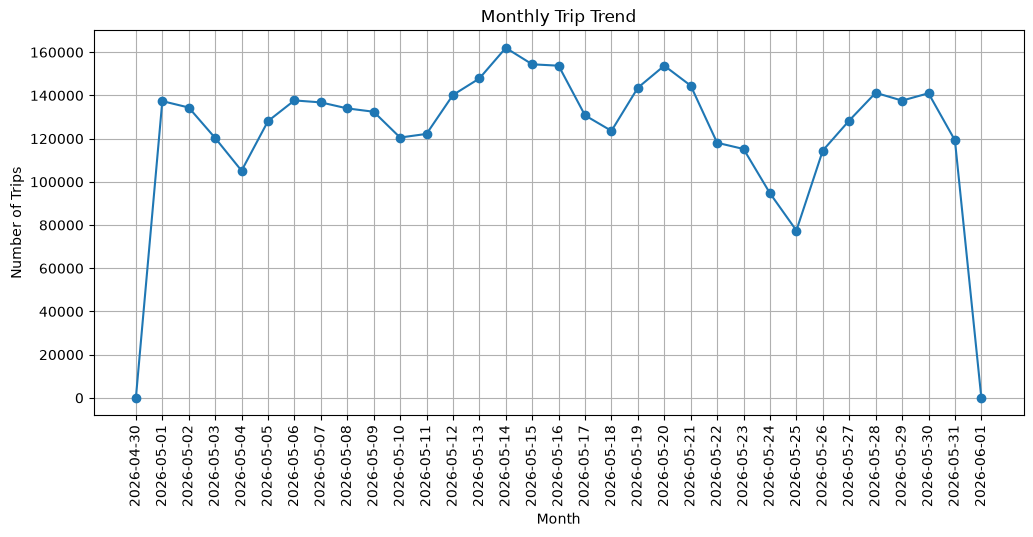

In [93]:

monthly_trips = (df.groupby(df['tpep_pickup_datetime'].dt.to_period('D')).size())

plt.figure(figsize=(12, 5))

plt.plot(monthly_trips.index.astype(str),monthly_trips.values,marker='o')

plt.title('Monthly Trip Trend')
plt.xlabel('Month')
plt.ylabel('Number of Trips')
plt.xticks(rotation=90)
plt.grid()

plt.show()

In [94]:
df.columns

Index(['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime',
       'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag',
       'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra',
       'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge',
       'total_amount', 'congestion_surcharge', 'Airport_fee',
       'cbd_congestion_fee', 'trip_duration_min', 'is_invalid_time',
       'is_invalid_date', 'trip_distance_km', 'is_distance_outlier',
       'fare_per_mile', 'is_fare_outlier', 'is_cash_tip_error',
       'expected_total', 'total_diff', 'is_total_mismatch',
       'is_invalid_location', 'pickup_hour'],
      dtype='object')

#### **Create dimensions table by using Data Dictionary**

**Vendors**

In [95]:
vend = {'VendorID':[1,2,6,7],
'Vendors_Name':['Creative Mobile Technologies, LLC ','Curb Mobility, LLC ','Myle Technologies Inc ','Helix ']
}

vendor = pd.DataFrame(vend)

vendor

,VendorID,Vendors_Name
0,1,"Creative Mobile Technologies, LLC"
1,2,"Curb Mobility, LLC"
2,6,Myle Technologies Inc
3,7,Helix


In [96]:
vendor.to_csv('Vendor_lookup.csv',index=False)

**RatecodeID**

In [97]:
rate = {'RatecodeID':[1,2,3,4,5,6,99],
        'Rate_Type':['Standard rate ','JFK','Newark','Nassau or Westchester','Negotiated fare ','Group ride','Null/unknown']}

Ratecode = pd.DataFrame(rate)

Ratecode

,RatecodeID,Rate_Type
0,1,Standard rate
1,2,JFK
2,3,Newark
3,4,Nassau or Westchester
4,5,Negotiated fare
5,6,Group ride
6,99,Null/unknown


In [98]:
Ratecode.to_csv('Ratecode_lookup.csv',index=False)

**payment_type**

In [99]:
payment = {'payment_type':[0,1,2,3,4,5,6],
           'payment_categories':['Flex Fare trip','Credit card','Cash','No charge','Dispute','Unknown','Voided trip']}

payment_type = pd.DataFrame(payment)

payment_type

,payment_type,payment_categories
0,0,Flex Fare trip
1,1,Credit card
2,2,Cash
3,3,No charge
4,4,Dispute
5,5,Unknown
6,6,Voided trip


In [100]:
payment_type.to_csv('Payment_lookup.csv',index=False)

**store_and_fwd_flag**

In [101]:
sff = {'store_and_fwd_flag':['Y','N'],'Store and Forward':['store and forward trip','not a store and forward trip']}

flag = pd.DataFrame(sff)

flag

,store_and_fwd_flag,Store and Forward
0,Y,store and forward trip
1,N,not a store and forward trip


In [102]:
flag.to_csv('Store_and_Forward_Flag_lookup.csv',index=False)

#### **Load all table to SQL**

In [103]:
# The 'df' DataFrame is too large to upload directly.
# Create the PostgreSQL table with the DataFrame's column names and data types,
# then load the complete dataset using the COPY command for efficient bulk insertion.


# df.head(0).to_sql('nyc_taxi', engine, if_exists="replace", index=False)
# data.to_sql('zone_lookup', engine, if_exists="replace",index=False)
# vendor.to_sql('vendor_lookup',engine,if_exists="replace",index=False)
# Ratecode.to_sql('ratecode_lookup',engine,if_exists="replace",index=False)
# payment_type.to_sql('payment_lookup',engine,if_exists="replace",index=False)
# flag.to_sql('store_and_forward_flag_lookup',engine,if_exists="replace",index=False)
